# Digital Twin Engine: workflow and HPC roles

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/23-dte-workflows.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/23-dte-workflows.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `c4d988ad43aea25ae0f8482e8e929ec15bc63b67d2d20c57a7b6ac4c679dcaf9`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# Digital Twin Engine: workflow and HPC roles

**Lesson 23 · Original synthetic data · Independent educational project**

## Objectives

Model a dependency graph and its critical path; separate local orchestration patterns from HPC execution.

[Previous](22-capstone.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/23-dte-workflows.ipynb) · [Next](24-polytope.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=23-dte-workflows.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

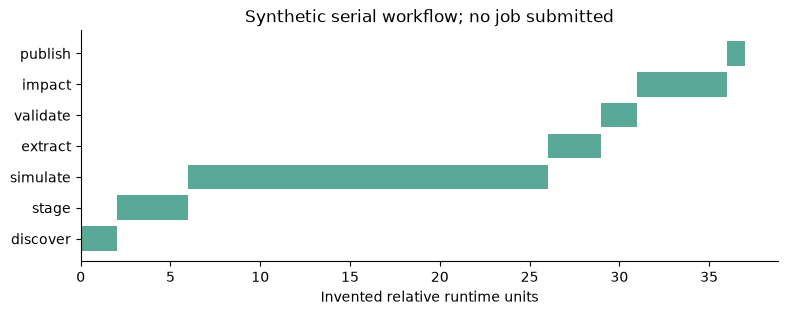

Critical path: 37 relative units


In [2]:
tasks = {"discover": (2, []), "stage": (4, ["discover"]), "simulate": (20, ["stage"]),
         "extract": (3, ["simulate"]), "validate": (2, ["extract"]),
         "impact": (5, ["validate"]), "publish": (1, ["impact"])}
finish = {}
for name, (duration, parents) in tasks.items():
    assert all(parent in finish for parent in parents), "Tasks must be topologically ordered"
    finish[name] = max([finish[parent] for parent in parents] or [0]) + duration
assert finish["publish"] == 37
fig, ax = plt.subplots(figsize=(9, 3))
for row, (name, (duration, parents)) in enumerate(tasks.items()):
    ax.barh(name, duration, left=finish[name]-duration, color="#58a997")
ax.set(xlabel="Invented relative runtime units", title="Synthetic serial workflow; no job submitted")
plt.show()
print("Critical path:", finish["publish"], "relative units")

## Exercise

Add a postprocessing branch that can run after extraction. Calculate when both branches finish and explain where extra workers help.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interpretation and limits

The Digital Twin Engine connects workflows, data handling and simulation infrastructure. ECMWF develops it for use with initial twins on European supercomputing resources. The graph here only teaches dependencies; it has no scheduler, allocation, model executable or production connection.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://destine.ecmwf.int/digital-twin-engine/) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).